# Exercise 6: NN from the scratch and Loss Functions


## Loss Functions

Different loss function in regression case. 

Simple MLP neural network and the dataset is generated using Sklearn's _make_regression_-function. Define loss function, print the value of loss function and plot the results. 

In [1]:
# MLP for regression
import tensorflow as tf
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import SGD
from matplotlib import pyplot

# Generate regression dataset
X, y = make_regression(n_samples=2000, n_features=20, noise=0.1, random_state=1) #default target = 1
# standardize dataset
X = StandardScaler().fit_transform(X)
y = StandardScaler().fit_transform(y.reshape(len(y),1))[:,0]

# split into train and test
n_train = 1000 #50/50
trainX, testX = X[:n_train, :], X[n_train:, :]
trainy, testy = y[:n_train], y[n_train:]

In [2]:
# # Create NN using Keras
# # Input layer = Define
# # Hidden layer: Dense, number of nodes = 25-50, activation='relu,kernel_initializer='he_uniform' '
# # Output = Define
# model = Sequential()
# model.add(Dense(25, input_dim=20, activation='relu', kernel_initializer='he_uniform'))
# model.add(Dense(1, activation='linear'))
# opt = SGD(learning_rate=0.01, momentum=0.9)

### Mean Squared Error (MSE)

Train: 0.001, Test: 0.001


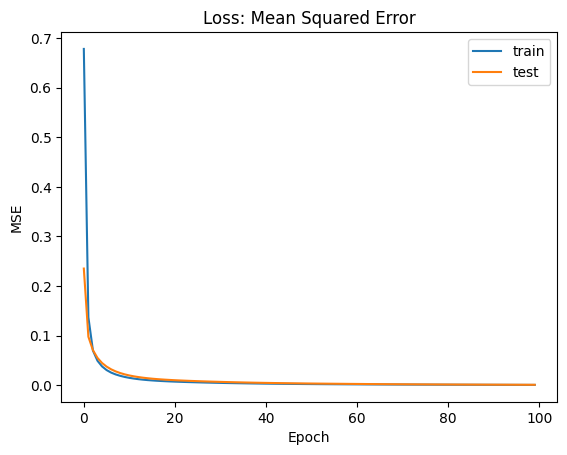

In [3]:
# Create NN using Keras
# Input layer = Define
# Hidden layer: Dense, number of nodes = 25-50, activation='relu,kernel_initializer='he_uniform' '
# Output = Define
tf.keras.utils.set_random_seed(1)
model = Sequential()
model.add(Input(shape=(20,)))
#model.add(Dense(25, input_dim=20, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(25, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(1, activation='linear'))
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile: opt defined above, loss = mse
model.compile(loss='mean_squared_error', optimizer=opt)

# fit model: validation_data=(testX, testy), epochs=100
history = model.fit(trainX, trainy, validation_data=(testX, testy), epochs=100, verbose=0)

# evaluate the model, print 
train_mse = model.evaluate(trainX, trainy, verbose=0)
test_mse = model.evaluate(testX, testy, verbose=0)

print('Train: %.3f, Test: %.3f' % (train_mse, test_mse))

# plot loss during training: loss and val_loss
pyplot.title('Loss: Mean Squared Error')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.xlabel('Epoch')
pyplot.ylabel('MSE')
pyplot.legend()
pyplot.show()


### Mean Absolute Error (MAE)

/Users/dineshbisht/masterdegree/myproject_env/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Train: 0.024, Test: 0.024


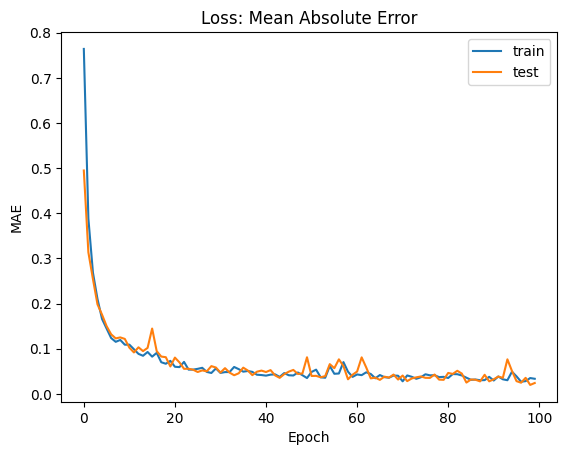

In [4]:
# Create NN using Keras
# Input layer = Define
# Hidden layer: Dense, number of nodes = 25-50, activation='relu,kernel_initializer='he_uniform' '
# Output = Define
tf.keras.utils.set_random_seed(1)
model = Sequential()
model.add(Dense(25, input_dim=20, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(1, activation='linear'))
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile: opt defined above, loss = mae
model.compile(loss='mean_absolute_error', optimizer=opt)

# fit model: validation_data=(testX, testy), epochs=100
history = model.fit(trainX, trainy, validation_data=(testX, testy), epochs=100, verbose=0)

# evaluate the model, print 
train_msa = model.evaluate(trainX, trainy, verbose=0)
test_msa = model.evaluate(testX, testy, verbose=0)

print('Train: %.3f, Test: %.3f' % (train_msa, test_msa))

# plot loss during training: loss and val_loss
pyplot.title('Loss: Mean Absolute Error')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.xlabel('Epoch')
pyplot.ylabel('MAE')
pyplot.legend()
pyplot.show()

### Huber loss

Train: 0.001, Test: 0.002


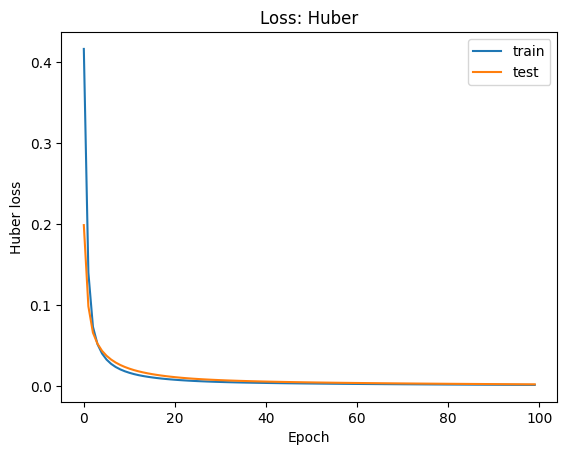

In [5]:
# Create NN using Keras
# Input layer = Define
# Hidden layer: Dense, number of nodes = 25-50, activation='relu,kernel_initializer='he_uniform' '
# Output = Define
tf.keras.utils.set_random_seed(1)
model = Sequential()
model.add(Dense(25, input_dim=20, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(1, activation='linear'))
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile: opt defined above, loss = tf.keras.losses.Huber()
model.compile(loss=tf.keras.losses.Huber(), optimizer=opt)

# fit model
history = model.fit(trainX, trainy, validation_data=(testX, testy), epochs=100, verbose=0)

# evaluate the model
train_huber = model.evaluate(trainX, trainy, verbose=0)
test_huber = model.evaluate(testX, testy, verbose=0)

print('Train: %.3f, Test: %.3f' % (train_huber, test_huber))

# plot loss during training
pyplot.title('Loss: Huber')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.xlabel('Epoch')
pyplot.ylabel('Huber loss')
pyplot.legend()
pyplot.show()

## Conclusion

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing them__

Write summary of results

In this exercise I trained the same simple MLP (20 inputs, 25 hidden nodes, 1 output) on the
same regression data with three different loss functions MSE, MAE and Huber. The optimizer,
the number of epochs (100) and the starting weights (same random seed) were the same, so the
only difference was the loss function.

#### Results
| Loss | Train | Test |
|---|---|---|
| MSE | 0.001 | 0.001 |
| MAE | 0.024 | 0.024 |
| Huber | 0.001 | 0.002 |

- All three losses learned the task. The loss started high and dropped quickly in the first few epochs. 
  For comparison, a model that always predicts the average would have an MSE of about 1.0.
- None of the models overfitted. In all three plots the train and test curves are almost on top
  of each other, and the final values are very close.
- MSE and Huber gave smooth curves. MAE was noisier and did not settle as smoothly, probably
  because its gradient stays the same size when the error becomes small.
- The loss values cannot be compared directly as numbers, because each loss measures the error
  in a different way. For example, MAE looks larger than MSE, but that does not mean its
  predictions are worse. 

## What I learned
The loss function defines what the model tries to minimize, so it changes how the training
behaves. On this dataset the data is clean and has almost no outliers, so the advantage of MAE
and Huber for outliers was not visible, and MSE worked well. With data that has outliers, MAE
or Huber could be the better choice. I also learned that the starting weights change the
results a little, so I fixed the random seed to compare the losses fairly.

## AI Usage
I used AI as an assistant in this exercise. It helped me complete the code for different
loss functions, explained the concepts I did not understand (such as how the loss functions
differ and how to read the loss curves), and helped me draft the conclusion. I ran the notebook
myself and checked that the conclusion matches my results.